## **Case - Mall Customer Segmentation**
---
Sebuah pusat perbelanjaan ingin memahami perilaku pelanggannya dengan lebih baik. Selama ini, semua pelanggan diperlakukan sama dalam strategi pemasaran, padahal setiap pelanggan memiliki karakteristik dan kebiasaan belanja yang berbeda. Akibatnya, promosi sering kali tidak tepat sasaran dan tidak efektif Manajemen ingin melakukan segmentasi pelanggan berdasarkan data seperti usia, jenis kelamin, pendapatan tahunan, dan kebiasaan belanja (spending score). Dengan membagi pelanggan ke dalam beberapa kelompok yang memiliki kesamaan, mall dapat merancang strategi promosi yang lebih personal, meningkatkan loyalitas pelanggan, dan mengoptimalkan pendapatan.

![](https://www.cleartouch.in/wp-content/uploads/2023/02/Customer-Segmentation.png)

# **Importing All Necessary Python Libraries**

In [ ]:
# Data Manipulation
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

# Preprocessing
from sklearn.preprocessing import MinMaxScaler

# Evaluation
from sklearn.metrics import silhouette_score, davies_bouldin_score

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
df = pd.read_csv("/content/drive/MyDrive/Business Analytics/Mall_Customers.csv")
df.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [ ]:
# See from univariate
col_to_drop = ["CustomerID", "Genre", "Age"]

df = df.drop(columns = col_to_drop)
df.head()

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [ ]:
# Normalisasi
scaler = MinMaxScaler()
scaler.fit(df)
df = scaler.transform(df)

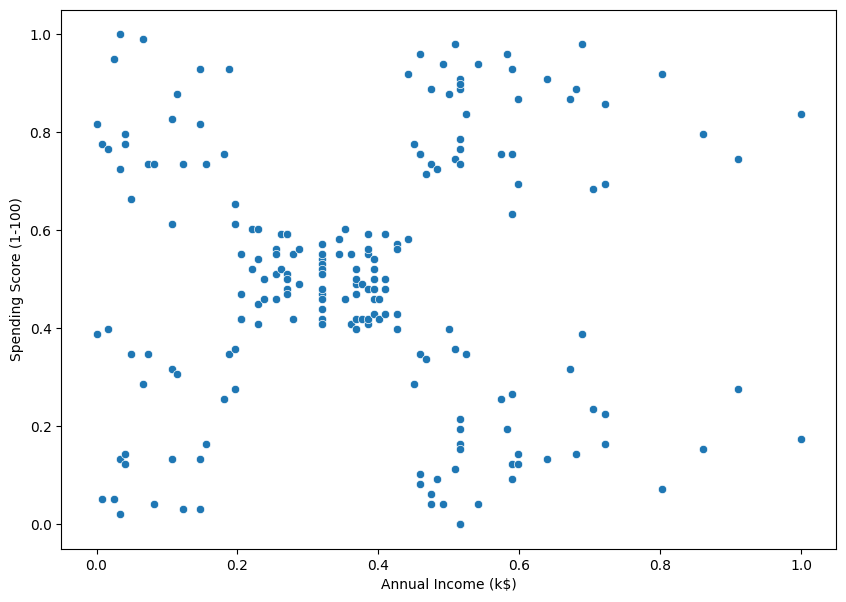

In [ ]:
# Visualisasikan
df = pd.DataFrame(df, columns=["Annual Income (k$)", "Spending Score (1-100)"])

fig, ax = plt.subplots(figsize=(10, 7))
sns.scatterplot(data=df,
                x="Annual Income (k$)",
                y="Spending Score (1-100)",
                ax=ax)
plt.show()

- Kita ingin representasikan data-data ini dengan cara mengelompokkan data-data yang sejenis (membuat cluster)

---
# Algoritma k-Means Clustering

1. Pilih jumlah cluster ($k$)
2. Generate centroid untuk masing-masing cluster. Artinya akan ada $k$ centroid.
3. Update anggota cluster.
4. Update centroid.
5. Update anggota cluster.
6. Ulangi **langkah 4 & 5** hingga seluruh centroid tidak berubah.

**1. Pilih jumlah cluster, $k$**

In [ ]:
# Melihat dari gambar
n_clust = 5

**2. Generate centroid untuk masing-masing cluster**

- Dibuat secara random

In [ ]:
centroid = np.random.random((n_clust, df.shape[1]))

centroid[:, 0] = centroid[:, 0] * np.max(df["Annual Income (k$)"])
centroid[:, 1] = centroid[:, 1] * np.max(df["Spending Score (1-100)"])

centroid

# Kolom --> fitur
# Baris --> centroid

array([[0.66379445, 0.05078865],
       [0.27269377, 0.03097735],
       [0.48021211, 0.69158973],
       [0.29507546, 0.62650622],
       [0.09362224, 0.63527642]])

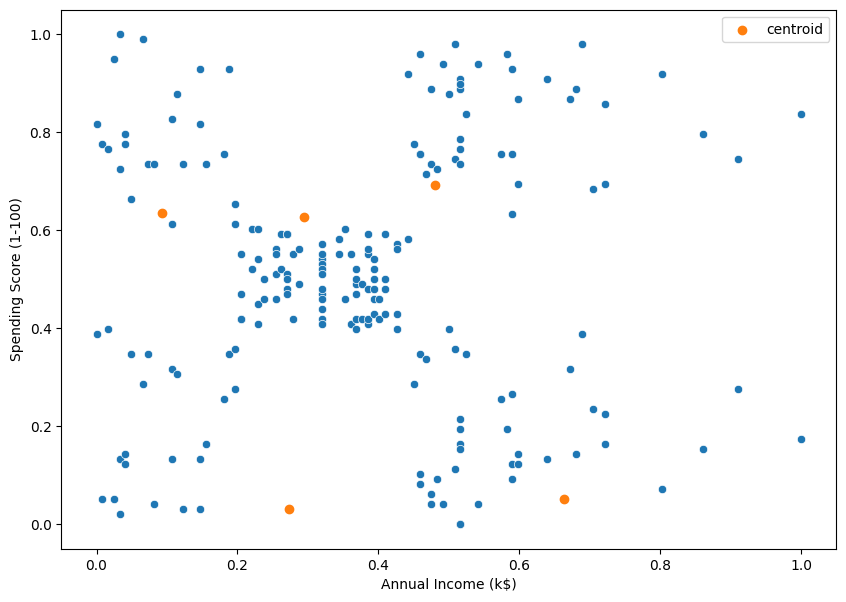

In [ ]:
# Visualisasikan
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(10, 7))

sns.scatterplot(data = df,
                x = "Annual Income (k$)",
                y = "Spending Score (1-100)",
                ax = ax)
ax.scatter(centroid[:, 0], centroid[:, 1], label="centroid")

plt.legend()
plt.show()

**3. Update Anggota Cluster**

In [ ]:
# Fungsi untuk menentukan data masuk ke centroid mana
def clusterAssignment(df, centroid):

    n = df.shape[0]       # banyaknya data
    k = centroid.shape[0] # banyaknya centroid / cluster

    c = np.zeros(n)       # alamat data --> ukuran sama dengan jumlah data

    # Mencari alamat data
    for i in range(n):

        # Define data ke-i
        data_i = df.loc[i]

        # cari list distance yang diisi jarak data ke masing-masing cluster
        list_distance = np.zeros(k)
        for j in range(k):

            # Define centroid ke-j
            centroid_j = centroid[j]

            # Hitung distance antara data_i - centroid_j
            list_distance[j] = np.linalg.norm(data_i - centroid_j)

        # Alamat data adalah jarak terkecil
        c[i] = np.argmin(list_distance) + 1  # +1 biar cluster mulai dari 1

    return c

# Pemanggilan fungsi
c = clusterAssignment(df=df, centroid=centroid)
c

array([5., 5., 2., 5., 5., 5., 2., 5., 2., 5., 2., 5., 2., 5., 2., 5., 5.,
       5., 2., 5., 5., 5., 2., 5., 2., 5., 5., 5., 2., 5., 2., 5., 2., 5.,
       2., 5., 2., 5., 2., 5., 4., 5., 4., 4., 2., 4., 4., 4., 4., 4., 4.,
       4., 4., 4., 4., 4., 4., 4., 4., 4., 4., 4., 4., 4., 4., 4., 4., 4.,
       4., 4., 4., 4., 4., 4., 4., 4., 4., 4., 4., 4., 4., 4., 4., 4., 4.,
       4., 4., 4., 4., 4., 4., 4., 4., 4., 4., 4., 4., 4., 4., 4., 4., 4.,
       4., 4., 4., 4., 4., 4., 4., 4., 4., 4., 4., 4., 4., 4., 4., 4., 4.,
       3., 3., 4., 3., 3., 2., 3., 4., 3., 2., 3., 2., 3., 4., 3., 1., 3.,
       1., 3., 1., 3., 1., 3., 3., 3., 1., 3., 3., 3., 1., 3., 1., 3., 1.,
       3., 1., 3., 1., 3., 1., 3., 1., 3., 1., 3., 1., 3., 1., 3., 1., 3.,
       1., 3., 1., 3., 1., 3., 1., 3., 1., 3., 1., 3., 1., 3., 1., 3., 1.,
       3., 1., 3., 1., 3., 1., 3., 1., 3., 1., 3., 1., 3.])

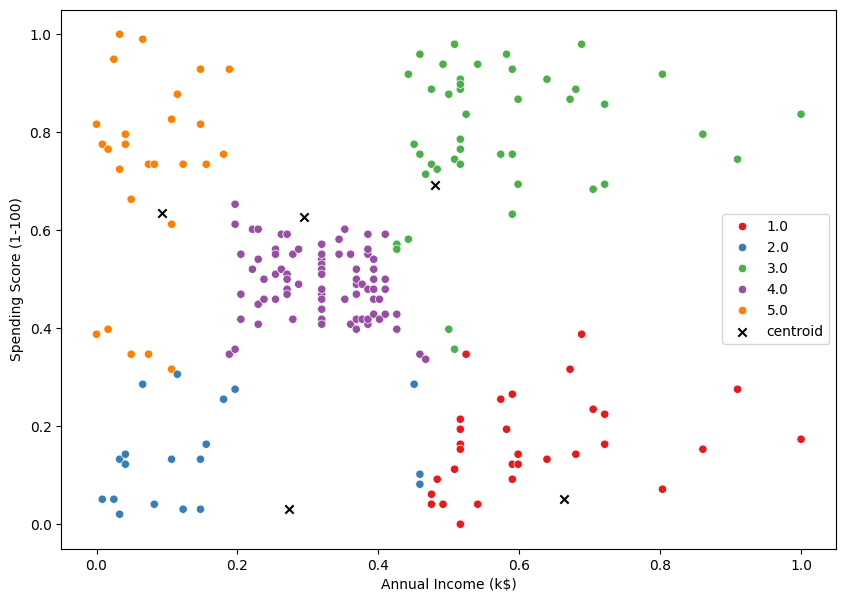

In [ ]:
# New data
data_new = df.copy()
data_new["cluster"] = c

# Visualisasikan
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(10, 7))

sns.scatterplot(data = data_new,
                x = "Annual Income (k$)",
                y = "Spending Score (1-100)",
                hue = "cluster",
                palette = "Set1",
                ax = ax)
ax.scatter(centroid[:, 0], centroid[:, 1],
           marker="x", c="k", label="centroid")

plt.legend()
plt.show()

**4. Update Centroid Baru**

In [ ]:
# Fungsi untuk update centroid baru berdasarkan rata-rata
def updateCentroid(df, centroid, c):

    # Ubah df ke numpy array
    data = np.array(df.copy())

    # Cari ukuran
    n = data.shape[0]
    p = data.shape[1]
    k = centroid.shape[0]

    # Cari centroid baru
    centroid_new = np.zeros((k, p))
    for j in range(k):

        # Cari data yang ada di cluster j
        data_in_cluster_j = data[c == j + 1]

        # Cegah error kalau cluster kosong
        if len(data_in_cluster_j) > 0:

            # Cari rata-rata data yang ada di cluster j
            centroid_new[j, :] = np.mean(data_in_cluster_j, axis=0)
        else:
            centroid_new[j, :] = centroid[j, :]  # pakai centroid lama

    return centroid_new

# Pemanggilan fungsi
centroid_new = updateCentroid(df=df, centroid=centroid, c=c)
centroid_new

array([[0.61686938, 0.15898618],
       [0.15099223, 0.13909774],
       [0.57209389, 0.78988868],
       [0.3192623 , 0.49183673],
       [0.07629256, 0.72056515]])

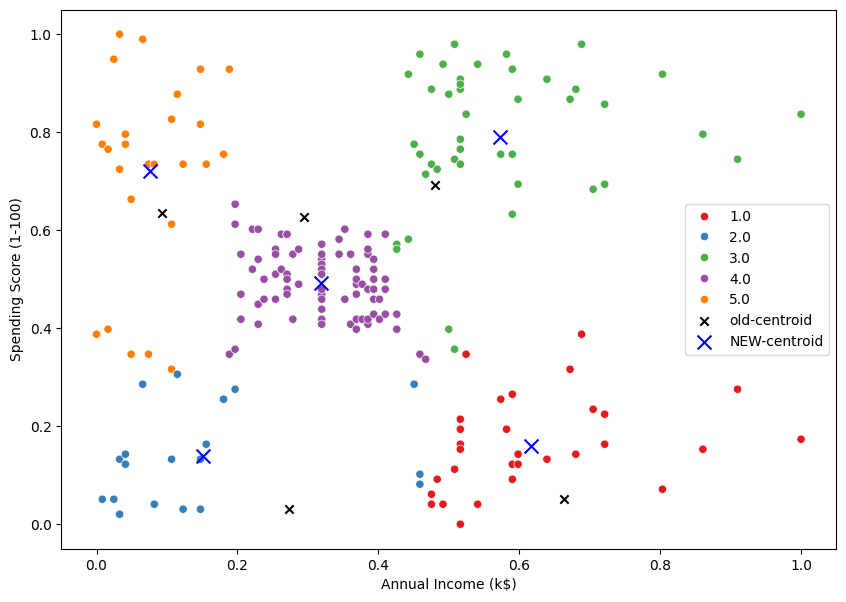

In [ ]:
# Visualisasikan
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(10, 7))

sns.scatterplot(data = data_new,
                x = "Annual Income (k$)",
                y = "Spending Score (1-100)",
                hue = "cluster",
                palette = "Set1",
                ax = ax)

ax.scatter(centroid[:, 0], centroid[:, 1],
           marker="x", c="k", label="old-centroid")

ax.scatter(centroid_new[:, 0], centroid_new[:, 1],
           marker="x", c="b", s=100, label="NEW-centroid")

plt.legend()
plt.show()

**TAMBAHAN: Buat Clustering Objective**

- Untuk menentukan jarak within cluster

In [ ]:
# Fungsi untuk menghitung nilai objective function (within-cluster distance)
def clusteringObjective(df, centroid, c):

    # Ubah df ke dalam numpy array
    data = np.array(df.copy())

    # Cari ukuran
    n = data.shape[0]
    k = centroid.shape[0]

    # Cari distance within cluster
    J_obj = 0
    for i in range(n):

        # Ekstrak data ke-i
        data_i = data[i]
        cluster_data_i = int(c[i] - 1)
        centroid_data_i = centroid[cluster_data_i]

        # Hitung distance (kuadrat)
        distance_i = np.linalg.norm(data_i - centroid_data_i) ** 2

        # Tambahkan ke total jarak
        J_obj += distance_i

    # Rata-rata jarak per data
    J_obj = J_obj / n

    return J_obj

# Pemanggilan fungsi
J_obj = clusteringObjective(df=df, centroid=centroid_new, c=c)
J_obj

np.float64(0.024749693002410634)

**5. Buat Fungsi Total untuk melakukan seluruh perulangan**

In [ ]:
# Fungsi utama untuk melakukan clustering dengan algoritma K-Means.
def kmeansClustering(df, n_clust, max_iter=1000, epsilon=1e-6):

    # Inisialisasi
    J_obj_hist = []

    # Ukuran data
    n = df.shape[0]       # banyak data
    p = df.shape[1]       # banyak fitur
    k = n_clust           # banyak cluster

    # 1. Buat centroid awal secara acak
    centroid = np.random.random((n_clust, p))
    for i in range(p):
        col = df.columns[i]
        centroid[:, i] = centroid[:, i] * np.max(df[col])

    # 2. Iterasi K-Means
    for i in range(max_iter):

        # 2a. Assign data ke cluster
        c = clusterAssignment(df=df, centroid=centroid)

        # 2b. Hitung nilai objective function
        J_obj = clusteringObjective(df=df, centroid=centroid, c=c)
        J_obj_hist.append(J_obj)

        # 2c. Update centroid
        centroid_new = updateCentroid(df=df, centroid=centroid, c=c)

        # 2d. Cek kondisi berhenti
        condition_1 = np.linalg.norm(centroid_new - centroid) < epsilon
        condition_2 = i == max_iter - 1

        # Update centroid
        centroid = centroid_new.copy()

        if condition_1 or condition_2:
            break

    return centroid, c, J_obj_hist
t
# Pemanggilan fungsi
centroid, c, J_obj_hist = kmeansClustering(df=df, n_clust=5)
print(f'The final J_objective = {J_obj_hist[-1]:.4f}')

The final J_objective = 0.0179


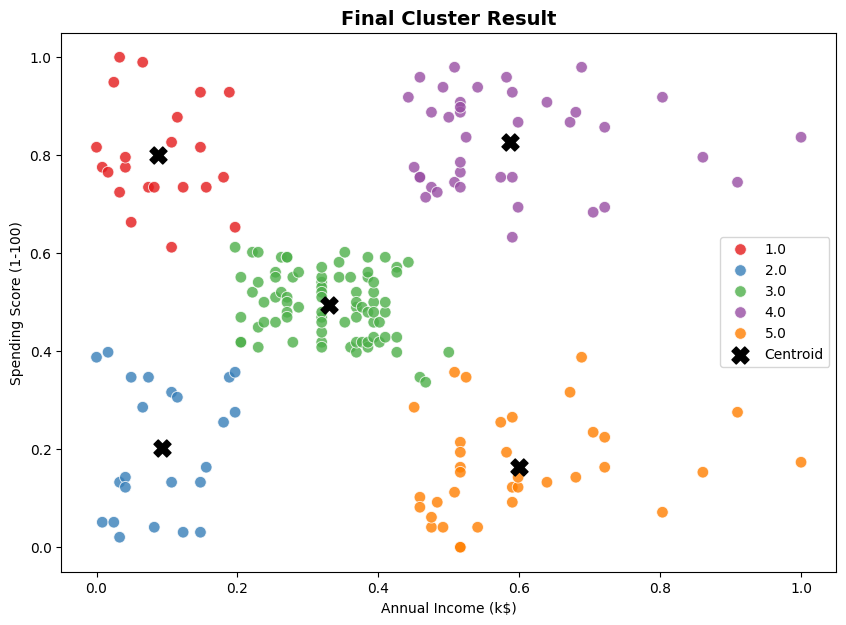

In [ ]:
# Plot Final Cluster
df_new = df.copy()
df_new["cluster"] = c

# Visualisasikan
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(10, 7))

sns.scatterplot(
    data=df_new,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="cluster",
    palette="Set1",
    ax=ax,
    s=70,
    alpha=0.8
)

# Plot centroid
ax.scatter(
    centroid[:, 0],
    centroid[:, 1],
    marker="X",
    c="black",
    s=150,
    label="Centroid"
)

ax.set_title("Final Cluster Result", fontsize=14, fontweight='bold')
ax.legend()
plt.show()

# **Using Library SKLEARN**

In [ ]:
from sklearn.cluster import KMeans

In [ ]:
df_sklearn = pd.read_csv("/content/drive/MyDrive/Business Analytics/Mall_Customers.csv")
df_sklearn.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [ ]:
# See from univariate
col_to_drop = ["CustomerID", "Genre", "Age"]

df_sklearn = df_sklearn.drop(columns = col_to_drop)
df_sklearn.head()

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [ ]:
scaler = MinMaxScaler()
scaler.fit(df_sklearn)
df_sklearn = scaler.transform(df_sklearn)

In [ ]:
# Buat objek
cluster_object = KMeans(n_clusters = 5)

# Fit objek
cluster_object.fit(df_sklearn)

KMeans(n_clusters=5)

In [ ]:
# Ekstrak principal components
cluster_object.labels_

array([3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4,
       3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 2,
       3, 4, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 0, 1, 0, 2, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 2, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0,
       1, 0], dtype=int32)

In [ ]:
# Ekstrak centroid
cluster_object.cluster_centers_

array([[0.58638083, 0.82783883],
       [0.59631148, 0.16921769],
       [0.32858607, 0.49706633],
       [0.09265859, 0.20319432],
       [0.08792846, 0.79962894]])

In [ ]:
# Ekstrak J_obj/inertia
cluster_object.inertia_

3.584755114930934

In [ ]:
print(type(cluster_object.cluster_centers_))
print(cluster_object.cluster_centers_.shape)

<class 'numpy.ndarray'>
(5, 2)


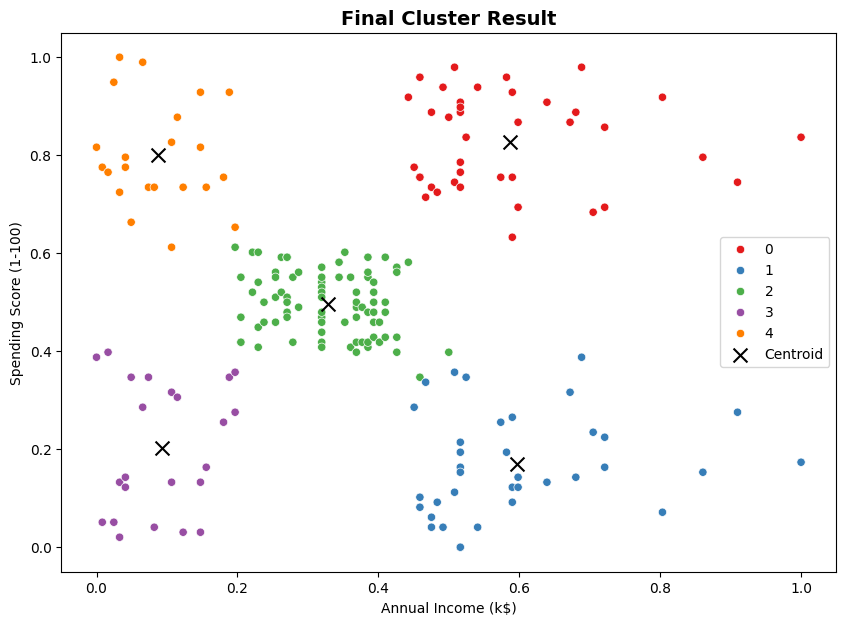

In [ ]:
# Plot Final Cluster
data_new_sklearn = pd.DataFrame(df_sklearn.copy(), columns=["Annual Income (k$)", "Spending Score (1-100)"])
data_new_sklearn["cluster"] = cluster_object.labels_

# Buat figure
fig, ax = plt.subplots(figsize=(10, 7))

# Scatter plot data
sns.scatterplot(
    data=data_new_sklearn,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="cluster",
    palette="Set1",
    ax=ax
)

# Ambil koordinat centroid dari KMeans
centroids = cluster_object.cluster_centers_

# Plot centroid dengan tanda 'x' hitam
ax.scatter(
    centroids[:, 0],  # sumbu X
    centroids[:, 1],  # sumbu Y
    marker="x",
    c="k",
    s=100,
    label="Centroid"
)

ax.set_title("Final Cluster Result", fontsize=14, fontweight='bold')
ax.legend()
plt.show()

**6. Evaluasi**

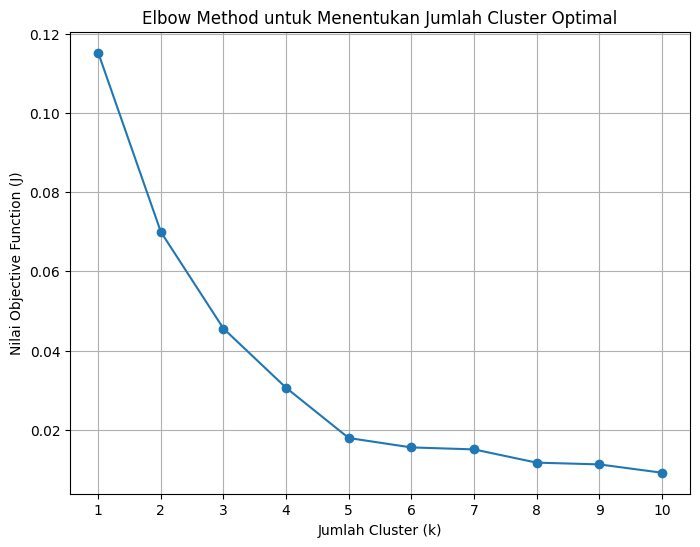

In [ ]:
# Visualisasi Elbow Method
k_values = range(1, 11)
J_values = []

for k in k_values:
    # centroid, c, J_obj_hist = kmeansClustering(df=df, n_clust=k)
    # J_values.append(J_obj_hist[-1])

    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(df_sklearn)
    J_values.append(kmeans.inertia_)

plt.figure(figsize=(8, 6))
plt.plot(k_values, J_values, marker='o', linestyle='-')
plt.title('Elbow Method untuk Menentukan Jumlah Cluster Optimal')
plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('Nilai Objective Function (J)')
plt.xticks(k_values)
plt.grid(True)
plt.show()


In [ ]:
# Evaluation
k_values = range(2, 11)
results = []

for k in k_values:

    # from scratch
    centroid, c, J_obj_hist = kmeansClustering(df=df, n_clust=k)
    sil = silhouette_score(df, c)
    dbi = davies_bouldin_score(df, c)

    # from library
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_sklearn = kmeans.fit_predict(df_sklearn)
    sil_sklearn = silhouette_score(df_sklearn, labels_sklearn)
    dbi_sklearn = davies_bouldin_score(df_sklearn, labels_sklearn)

    results.append({
        'k': k,
        'Silhouette': sil,
        'DBI': dbi,
        'Silhouette (Sklearn)': sil_sklearn,
        'DBI (Sklearn)': dbi_sklearn
    })

# Result
results_df = pd.DataFrame(results)
print(results_df.round(4))

    k  Silhouette     DBI  Silhouette (Sklearn)  DBI (Sklearn)
0   2      0.3447  1.1364                0.3334         1.1371
1   3      0.4468  0.7856                0.4515         0.8463
2   4      0.4962  0.7033                0.4962         0.7033
3   5      0.5595  0.5678                0.5595         0.5678
4   6      0.5433  0.6488                0.5358         0.6939
5   7      0.5121  0.7316                0.5168         0.7686
6   8      0.4825  0.7430                0.4298         0.8259
7   9      0.4177  0.8174                0.4416         0.7941
8  10      0.4608  0.7208                0.4324         0.7976


**7. Kesimpulan**

Model K-Means dengan 5 cluster memberikan hasil terbaik berdasarkan nilai Silhouette Score dan Davies–Bouldin Index. Secara empiris, konfigurasi lima cluster ini mampu menggambarkan perilaku pelanggan yang berbeda secara jelas, serta telah banyak digunakan dalam berbagai penerapan nyata di dunia bisnis ritel.
Kelima segmen pelanggan tersebut meliputi:

1. **Low Income, Low Spending** : pelanggan dengan pendapatan rendah dan pengeluaran rendah.
2. **Low Income, High Spending** : pelanggan berpendapatan rendah namun memiliki kecenderungan belanja tinggi.
3. **High Income, Low Spending** : pelanggan berpendapatan tinggi namun cenderung jarang berbelanja.
4. **Medium Income, Medium Spending** : pelanggan dengan pendapatan dan pengeluaran rata-rata.
5. **High Income, High Spending** : pelanggan berpendapatan tinggi yang aktif berbelanja dan memiliki potensi loyalitas tinggi.